# Random Forest V4

For V4, I compared sqrt, log2 and 15 features per split. I kept 20 trees and depth 8 for both datasets, using the same training and validation samples as V3.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from src.data_loader import load_task, split_train_val
from src.models.random_forest import RandomForest

result_dir = project_root / "results/random_forest"
data_dir = project_root.parent / "data"
feature_settings = ["sqrt", "log2", 15]
v3_summary = pd.read_csv(result_dir / "random_forest_v3_summary.csv", float_precision="round_trip")
summary_rows = []
selected = {}
print(f"Python {platform.python_version()}, NumPy {np.__version__}, pandas {pd.__version__}")


Python 3.14.3, NumPy 2.4.3, pandas 3.0.1


I started by testing the different feature settings on the image dataset.

In [2]:
task = "image"
v3_best = v3_summary.loc[v3_summary.dataset == task].sort_values(
    ["validation_accuracy", "max_depth"], ascending=[False, True]).iloc[0]
n_trees = int(v3_best.n_trees)
max_depth = int(v3_best.max_depth)
assert n_trees == 20 and max_depth == 8
X, y, _, _ = load_task(task, data_dir=data_dir)
X_train_full, X_val_full, y_train_full, y_val_full = split_train_val(X, y, val_fraction=0.2, seed=42)
X_train, y_train = X_train_full[:200], y_train_full[:200]
X_val, y_val = X_val_full[:200], y_val_full[:200]
assert X_train.shape == X_val.shape == (200, 500)
v3_validation = pd.read_csv(result_dir / f"random_forest_v3_{task}_validation.csv")
assert v3_validation.validation_index.tolist() == list(range(200))
assert v3_validation.actual_label.tolist() == y_val.tolist()
image_rows = []
image_predictions = {}
image_actual = y_val.copy()
for n_features in feature_settings:
    clf = RandomForest(n_trees=n_trees, max_depth=max_depth, min_samples=1, n_features=n_features, seed=42)
    start = perf_counter()
    assert clf.fit(X_train, y_train) is clf
    fit_time = perf_counter() - start
    training_accuracy = clf.score(X_train, y_train)
    start = perf_counter()
    predictions = clf.predict(X_val)
    prediction_time = perf_counter() - start
    validation_accuracy = sum(p == t for p, t in zip(predictions, y_val)) / 200
    oob_accuracy = clf.oob_score(y_train)
    assert len(clf.trees) == 20 and len(predictions) == 200
    assert all(t.criterion == "entropy" for t in clf.trees)
    assert all(0 <= p <= 49 for p in predictions)
    if n_features == "sqrt":
        assert predictions == v3_validation.predicted_label.tolist()
        assert training_accuracy == v3_best.training_accuracy
        assert validation_accuracy == v3_best.validation_accuracy
        assert oob_accuracy == v3_best.oob_accuracy
        print(f"sqrt reproduces all selected V3 predictions and train/validation/OOB scores exactly.")
    image_predictions[n_features] = predictions
    row = {"dataset": task, "version": "V4", "n_trees": n_trees,
           "max_depth": max_depth, "min_samples": 1, "n_features": n_features,
           "criterion": "entropy", "normalized": False, "training_samples": 200,
           "validation_samples": 200, "training_accuracy": training_accuracy,
           "validation_accuracy": validation_accuracy, "oob_accuracy": oob_accuracy,
           "fit_time_seconds": fit_time, "prediction_time_seconds": prediction_time}
    image_rows.append(row)
    print(f"{task} features={n_features}: training={training_accuracy:.2%}, validation={validation_accuracy:.2%}, OOB={oob_accuracy:.2%} on {sum(bool(v) for v in clf._oob_preds.values())}/200")
    print(f"Fit={fit_time:.9f} s, predict={prediction_time:.9f} s")
summary_rows.extend(image_rows)


sqrt reproduces all selected V3 predictions and train/validation/OOB scores exactly.
image features=sqrt: training=99.00%, validation=7.50%, OOB=4.00% on 200/200
Fit=0.864579083 s, predict=0.002905500 s
image features=log2: training=98.50%, validation=4.50%, OOB=2.00% on 200/200
Fit=0.365570000 s, predict=0.003110208 s
image features=15: training=98.50%, validation=3.00%, OOB=1.00% on 200/200
Fit=0.629097292 s, predict=0.003095375 s


Then I repeated the same experiment with the sentiment dataset.

In [3]:
task = "sentiment"
v3_best = v3_summary.loc[v3_summary.dataset == task].sort_values(
    ["validation_accuracy", "max_depth"], ascending=[False, True]).iloc[0]
n_trees = int(v3_best.n_trees)
max_depth = int(v3_best.max_depth)
assert n_trees == 20 and max_depth == 8
X, y, _, _ = load_task(task, data_dir=data_dir)
X_train_full, X_val_full, y_train_full, y_val_full = split_train_val(X, y, val_fraction=0.2, seed=42)
X_train, y_train = X_train_full[:200], y_train_full[:200]
X_val, y_val = X_val_full[:200], y_val_full[:200]
assert X_train.shape == X_val.shape == (200, 768)
v3_validation = pd.read_csv(result_dir / f"random_forest_v3_{task}_validation.csv")
assert v3_validation.validation_index.tolist() == list(range(200))
assert v3_validation.actual_label.tolist() == y_val.tolist()
sentiment_rows = []
sentiment_predictions = {}
sentiment_actual = y_val.copy()
for n_features in feature_settings:
    clf = RandomForest(n_trees=n_trees, max_depth=max_depth, min_samples=1, n_features=n_features, seed=42)
    start = perf_counter()
    assert clf.fit(X_train, y_train) is clf
    fit_time = perf_counter() - start
    training_accuracy = clf.score(X_train, y_train)
    start = perf_counter()
    predictions = clf.predict(X_val)
    prediction_time = perf_counter() - start
    validation_accuracy = sum(p == t for p, t in zip(predictions, y_val)) / 200
    oob_accuracy = clf.oob_score(y_train)
    assert len(clf.trees) == 20 and len(predictions) == 200
    assert all(t.criterion == "entropy" for t in clf.trees)
    assert all(0 <= p <= 2 for p in predictions)
    if n_features == "sqrt":
        assert predictions == v3_validation.predicted_label.tolist()
        assert training_accuracy == v3_best.training_accuracy
        assert validation_accuracy == v3_best.validation_accuracy
        assert oob_accuracy == v3_best.oob_accuracy
        print(f"sqrt reproduces all selected V3 predictions and train/validation/OOB scores exactly.")
    sentiment_predictions[n_features] = predictions
    row = {"dataset": task, "version": "V4", "n_trees": n_trees,
           "max_depth": max_depth, "min_samples": 1, "n_features": n_features,
           "criterion": "entropy", "normalized": False, "training_samples": 200,
           "validation_samples": 200, "training_accuracy": training_accuracy,
           "validation_accuracy": validation_accuracy, "oob_accuracy": oob_accuracy,
           "fit_time_seconds": fit_time, "prediction_time_seconds": prediction_time}
    sentiment_rows.append(row)
    print(f"{task} features={n_features}: training={training_accuracy:.2%}, validation={validation_accuracy:.2%}, OOB={oob_accuracy:.2%} on {sum(bool(v) for v in clf._oob_preds.values())}/200")
    print(f"Fit={fit_time:.9f} s, predict={prediction_time:.9f} s")
summary_rows.extend(sentiment_rows)


sqrt reproduces all selected V3 predictions and train/validation/OOB scores exactly.
sentiment features=sqrt: training=100.00%, validation=43.50%, OOB=45.50% on 200/200
Fit=4.582189375 s, predict=0.002401583 s
sentiment features=log2: training=100.00%, validation=41.50%, OOB=42.00% on 200/200
Fit=1.721975375 s, predict=0.002547709 s
sentiment features=15: training=100.00%, validation=41.50%, OOB=44.00% on 200/200
Fit=2.924988459 s, predict=0.002531167 s


I plotted training and validation accuracy to compare the feature settings.

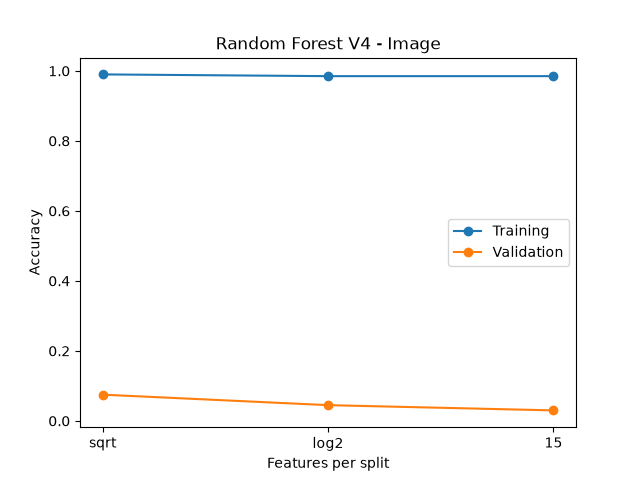

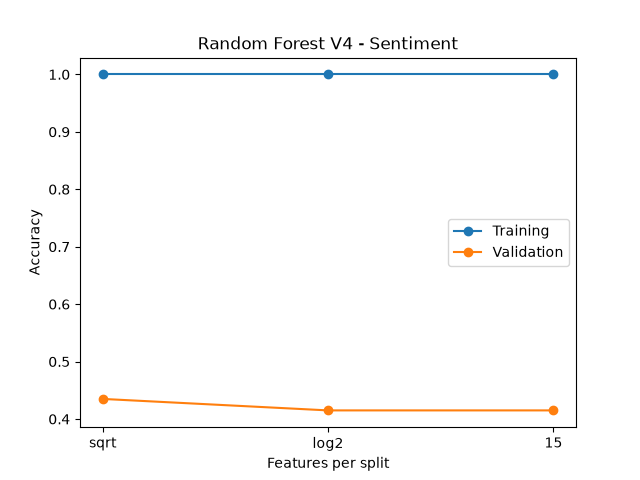

In [4]:
for task, rows in [("image", image_rows), ("sentiment", sentiment_rows)]:
    frame = pd.DataFrame(rows)
    plt.figure()
    plt.plot(frame.n_features.astype(str), frame.training_accuracy, marker="o", label="Training")
    plt.plot(frame.n_features.astype(str), frame.validation_accuracy, marker="o", label="Validation")
    plt.xlabel("Features per split")
    plt.ylabel("Accuracy")
    plt.title(f"Random Forest V4 - {task.capitalize()}")
    plt.xticks([str(value) for value in feature_settings])
    plt.legend()
    plt.savefig(result_dir / f"random_forest_v4_{task}_n_features.png")
    plt.show()


Finally, I selected the best feature setting for each dataset using validation accuracy and saved its predictions. If accuracies tie, I keep sqrt first, then log2, then 15.

In [5]:
summary = pd.DataFrame(summary_rows)
assert len(summary) == 6
summary.to_csv(result_dir / "random_forest_v4_summary.csv", index=False)
for task, rows, actual, prediction_map in [
    ("image", image_rows, image_actual, image_predictions),
    ("sentiment", sentiment_rows, sentiment_actual, sentiment_predictions),
]:
    best = rows[0]
    for row in rows[1:]:
        if row["validation_accuracy"] > best["validation_accuracy"]:
            best = row
    selected[task] = best
    path = result_dir / f"random_forest_v4_{task}_validation.csv"
    pd.DataFrame({"validation_index": range(200), "actual_label": actual,
                  "predicted_label": prediction_map[best["n_features"]]}).to_csv(path, index=False)
    saved = pd.read_csv(path)
    assert saved.shape == (200, 3) and not saved.isna().any().any()
    assert saved.validation_index.tolist() == list(range(200))
    assert saved.actual_label.tolist() == actual.tolist()
    assert saved.predicted_label.tolist() == prediction_map[best["n_features"]]
    assert sum(saved.actual_label == saved.predicted_label)/200 == best["validation_accuracy"]
    print(f"{task}: selected features={best['n_features']}, validation={best['validation_accuracy']:.2%}")
print(summary.to_string(index=False))
tracker_path = result_dir / "kaggle_scores.csv"
tracker = pd.read_csv(tracker_path, dtype=str, keep_default_na=False)
assert tracker.version.is_unique
previous_rows = tracker.loc[tracker.version != "V4"].to_dict("records")
v4_row = {"version": "V4", "image_validation_accuracy": selected["image"]["validation_accuracy"],
    "sentiment_validation_accuracy": selected["sentiment"]["validation_accuracy"],
    "kaggle_public_score": "", "submitted_to_kaggle": False, "submission_filename": "",
    "notes": f"Tested sqrt,log2,15 features per split; selected image={selected['image']['n_features']}, sentiment={selected['sentiment']['n_features']}; 20 trees and depth=8 each; min_samples=1; entropy; seed=42; original features; 200 train/200 validation per task. No Kaggle candidate."}
matching = tracker.version == "V4"
if matching.any():
    for col in ("image_validation_accuracy", "sentiment_validation_accuracy", "notes"):
        tracker.loc[matching, col] = str(v4_row[col])
else:
    tracker = pd.concat([tracker, pd.DataFrame([v4_row])], ignore_index=True)
assert tracker.version.is_unique
assert tracker.loc[tracker.version != "V4"].to_dict("records") == previous_rows
tracker.to_csv(tracker_path, index=False)


image: selected features=sqrt, validation=7.50%
sentiment: selected features=sqrt, validation=43.50%
  dataset version  n_trees  max_depth  min_samples n_features criterion  normalized  training_samples  validation_samples  training_accuracy  validation_accuracy  oob_accuracy  fit_time_seconds  prediction_time_seconds
    image      V4       20          8            1       sqrt   entropy       False               200                 200              0.990                0.075         0.040          0.864579                 0.002905
    image      V4       20          8            1       log2   entropy       False               200                 200              0.985                0.045         0.020          0.365570                 0.003110
    image      V4       20          8            1         15   entropy       False               200                 200              0.985                0.030         0.010          0.629097                 0.003095
sentiment      V4      

I selected sqrt for image (7.50% validation accuracy) and sqrt for sentiment (43.50%). Both sqrt models reproduced V3 exactly. These results use 200 validation examples per dataset.